# T9.5 — Stock-Market News → Ticker: Training & Evaluation Notebook

**SMAI Assignment 3 | IIIT Hyderabad | Tier 1**

This notebook demonstrates:
1. How our zero-shot classification pipeline works
2. Evaluation on curated Indian financial headlines
3. Analysis of results and limitations

---

## 1. Setup & Imports

In [4]:
# Install dependencies (uncomment on Colab)
!pip install transformers torch feedparser google-generativeai scikit-learn pandas matplotlib seaborn

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.5/81.5 kB 4.3 MB/s eta 0:00:00
  Created wheel for sgmllib3k: filename=sgmllib3k-1.0.0-py3-none-any.whl size=6046 sha256=8e1e4e81a21a8f52fcd20d6bacdc014eff952f702ed9b2a1ea60fdb002f5c5b0
  Stored in directory: /root/.cache/pip/wheels/03/f5/1a/23761066dac1d0e8e683e5fdb27e12de53209d05a4a37e6246
Successfully built sgmllib3k


In [5]:
import json
import re
import pandas as pd
import numpy as np
from transformers import pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ All imports successful")

✅ All imports successful


## 2. Load the Zero-Shot Classification Model

We use `facebook/bart-large-mnli`, a model trained on **Natural Language Inference (NLI)**.

### How Zero-Shot Classification Works
1. The model takes a **premise** (our news text) and a **hypothesis** (e.g., "This text is about Stock Market")
2. It outputs a probability that the hypothesis is true given the premise
3. We check all candidate labels and pick the highest-scoring one
4. **No training data needed** — the model's language understanding is enough!

In [6]:
# Load the zero-shot classification pipeline
# This downloads the model (~1.6GB) on first run
print("Loading BART-MNLI model (may take ~20 seconds)...")
classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=-1  # CPU — works on any laptop / Colab
)
print("✅ Model loaded successfully")

# Define our classification labels
LABELS = ["Stock Market", "Business", "Economy", "Technology", "Others"]

Loading BART-MNLI model (may take ~20 seconds)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✅ Model loaded successfully


## 3. Quick Demo: Classify a Single Article

In [7]:
# Example article
demo_text = "Reliance Industries expands telecom network. RIL invests Rs 5000 crore in Jio infrastructure."

result = classifier(demo_text, candidate_labels=LABELS)

print("Input:", demo_text)
print("\nResults:")
for label, score in zip(result['labels'], result['scores']):
    bar = '█' * int(score * 40)
    print(f"  {label:15s} {score:.3f} {bar}")
print(f"\n→ Predicted: {result['labels'][0]} (confidence: {result['scores'][0]:.1%})")

Input: Reliance Industries expands telecom network. RIL invests Rs 5000 crore in Jio infrastructure.

Results:
  Technology      0.373 ██████████████
  Business        0.301 ████████████
  Economy         0.155 ██████
  Others          0.140 █████
  Stock Market    0.032 █

→ Predicted: Technology (confidence: 37.3%)


## 4. Evaluation Dataset

We use a **hand-curated dataset of 38 Indian financial headlines** with ground-truth labels.
This is inspired by the [India Headlines News Dataset](https://kaggle.com/datasets/therohk/india-headlines-news-dataset) (21 years of headlines).

For a Tier 1 project, a small manual sample (30-50) is sufficient to demonstrate evaluation methodology.

In [8]:
# Evaluation dataset: (title, description, ground_truth_label)
EVAL_DATA = [
    # Stock Market (10)
    ("Sensex jumps 750 points as IT stocks rally", "Indian benchmark indices surged on strong quarterly earnings from TCS and Infosys", "Stock Market"),
    ("Nifty hits all-time high of 24,000", "The NSE Nifty 50 crossed the 24,000 mark for the first time, driven by banking and IT stocks", "Stock Market"),
    ("FIIs pull out Rs 5,000 crore from Indian markets", "Foreign institutional investors continued selling Indian equities amid rising US bond yields", "Stock Market"),
    ("Reliance shares surge 5% after Q2 results beat estimates", "Reliance Industries reported strong quarterly numbers with Jio subscriber additions", "Stock Market"),
    ("IPO market booms as 5 new issues hit the market this week", "Five companies are launching their IPOs this week on NSE and BSE", "Stock Market"),
    ("HDFC Bank stock falls 3% on weak loan growth guidance", "HDFC Bank shares declined after cautious outlook on credit growth", "Stock Market"),
    ("Midcap index outperforms Nifty 50 by wide margin", "Small and mid-cap stocks have delivered 40% returns this year vs 15% for large-caps", "Stock Market"),
    ("Adani Group stocks recover after credit upgrade", "Adani Enterprises gained on positive credit rating revision", "Stock Market"),
    ("Mutual fund SIP investments hit record Rs 20,000 crore", "Indian retail investors continue pouring money into equity mutual funds", "Stock Market"),
    ("Bears tighten grip as Sensex falls below 70,000", "Markets slumped on global cues with Sensex losing over 1000 points", "Stock Market"),
    # Business (8)
    ("Tata Group acquires Air India for Rs 18,000 crore", "Tata Sons won the bid to acquire the national carrier", "Business"),
    ("Zomato reports first-ever quarterly profit", "Food delivery platform turned profitable driven by Blinkit growth", "Business"),
    ("Amazon India expands warehouse network to 100 cities", "E-commerce giant investing Rs 5,000 crore in fulfillment centers", "Business"),
    ("Infosys wins $1.5 billion deal from European bank", "Infosys signed its largest deal ever for digital transformation", "Business"),
    ("Ola Electric files for Rs 5,500 crore IPO", "EV maker planning to raise capital for expanding manufacturing", "Business"),
    ("Flipkart valuation drops to $35 billion", "Walmart-backed Flipkart saw valuation cut as investors reassess growth", "Business"),
    ("Maruti Suzuki launches new hybrid SUV at Rs 12 lakh", "India's largest carmaker unveiled a hybrid vehicle for the SUV segment", "Business"),
    ("Bharti Airtel raises tariffs by 15%", "Telecom operator increased recharge prices citing rising costs", "Business"),
    # Economy (8)
    ("RBI cuts repo rate by 25 basis points to 6.25%", "Reserve Bank reduced lending rate for the first time in two years", "Economy"),
    ("India GDP grows 7.6% in Q3, beats all estimates", "Indian economy surprised analysts with robust performance", "Economy"),
    ("Inflation rises to 5.5% in March on higher food prices", "Consumer price inflation driven by vegetables and cereals", "Economy"),
    ("Rupee falls to record low of 84.5 against US dollar", "Indian rupee weakened amid capital outflows", "Economy"),
    ("Government announces Rs 2 lakh crore infrastructure push", "Finance ministry allocated major spending for roads and railways", "Economy"),
    ("India fiscal deficit widens to 5.8% of GDP", "Government deficit exceeded targets due to higher subsidy spending", "Economy"),
    ("GST collections cross Rs 2 lakh crore for first time", "GST revenue hit a record high indicating strong economic activity", "Economy"),
    ("Crude oil prices surge to $100, India faces inflation risk", "Rising crude prices threaten India's current account deficit", "Economy"),
    # Technology (7)
    ("ISRO successfully launches Gaganyaan test module", "India's space agency completed uncrewed test of human spaceflight", "Technology"),
    ("Indian startups raise $10 billion in 2024", "AI and deeptech companies attracted most investment", "Technology"),
    ("UPI transactions cross 15 billion monthly", "Digital payments growing rapidly with rural adoption", "Technology"),
    ("India launches 6G research initiative with IITs", "Government allocated Rs 500 crore for 6G research", "Technology"),
    ("Wipro launches AI-powered cybersecurity platform", "IT major unveiled AI-based security solution", "Technology"),
    ("Indian AI startups building local language models", "Startups developing LLMs for Hindi and regional languages", "Technology"),
    ("Semiconductor fab in Gujarat gets Cabinet approval", "Tata-PSMC chip manufacturing plant received clearance", "Technology"),
    # Others (5)
    ("India beats Australia to win Border-Gavaskar Trophy", "Indian cricket team retained the trophy with a series win", "Others"),
    ("PM Modi inaugurates new Parliament building", "Prime Minister laid foundation for events in new parliament", "Others"),
    ("Monsoon expected to be above normal: IMD", "IMD predicts 106% of long period average rainfall", "Others"),
    ("Jawan crosses Rs 1000 crore worldwide", "Shah Rukh Khan's film becomes highest grossing of the year", "Others"),
    ("Delhi pollution: Air quality drops to severe", "National capital recorded AQI above 400", "Others"),
]

print(f"Total evaluation samples: {len(EVAL_DATA)}")
print(f"\nSamples per category:")
from collections import Counter
counts = Counter(label for _, _, label in EVAL_DATA)
for label, count in sorted(counts.items()):
    print(f"  {label}: {count}")

Total evaluation samples: 38

Samples per category:
  Business: 8
  Economy: 8
  Others: 5
  Stock Market: 10
  Technology: 7


## 5. Run Classification on All Samples

In [9]:
# Classify all samples
y_true = []
y_pred = []
confidences = []

print("Running zero-shot classification on all samples...")
for i, (title, desc, true_label) in enumerate(EVAL_DATA):
    text = f"{title}. {desc}"
    result = classifier(text[:512], candidate_labels=LABELS)
    pred_label = result['labels'][0]
    confidence = result['scores'][0]

    y_true.append(true_label)
    y_pred.append(pred_label)
    confidences.append(confidence)

    if (i+1) % 10 == 0:
        print(f"  {i+1}/{len(EVAL_DATA)} done...")

print(f"\n✅ Classification complete!")
print(f"Overall Accuracy: {accuracy_score(y_true, y_pred):.1%}")

Running zero-shot classification on all samples...
  10/38 done...
  20/38 done...
  30/38 done...

✅ Classification complete!
Overall Accuracy: 68.4%


## 6. Classification Report

In [10]:
# Detailed classification report
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

Stock Market       0.90      0.90      0.90        10
    Business       0.83      0.62      0.71         8
     Economy       0.67      0.50      0.57         8
  Technology       0.67      0.86      0.75         7
      Others       0.29      0.40      0.33         5

    accuracy                           0.68        38
   macro avg       0.67      0.66      0.65        38
weighted avg       0.71      0.68      0.69        38



## 7. Confusion Matrix

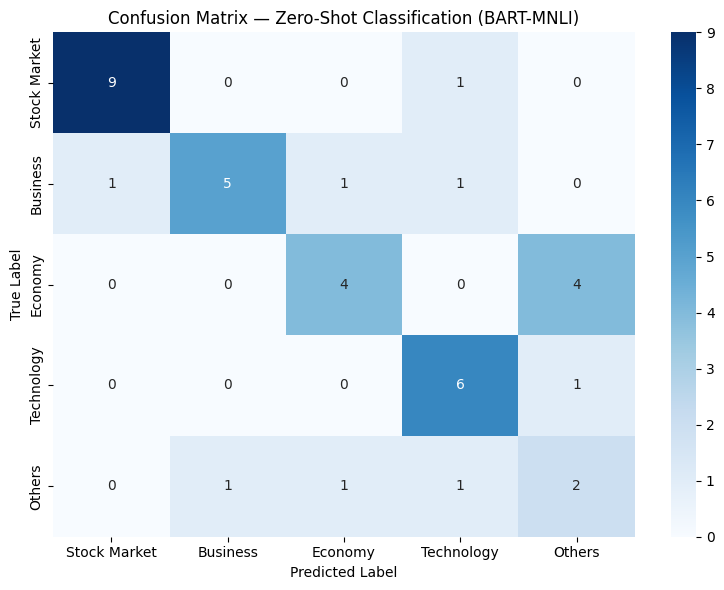

Saved: confusion_matrix.png


In [11]:
# Confusion matrix visualization
cm = confusion_matrix(y_true, y_pred, labels=LABELS)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix — Zero-Shot Classification (BART-MNLI)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: confusion_matrix.png")

## 8. Confidence Analysis

Average confidence by prediction correctness:
Correct
False    0.427914
True     0.555066



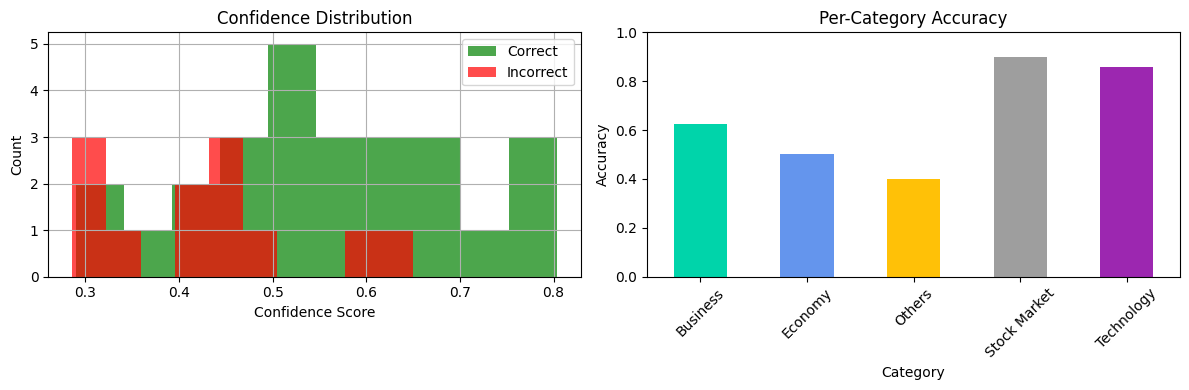

Saved: evaluation_results.png


In [12]:
# Analyze confidence scores
df = pd.DataFrame({
    'True Label': y_true,
    'Predicted': y_pred,
    'Confidence': confidences,
    'Correct': [t == p for t, p in zip(y_true, y_pred)]
})

print("Average confidence by prediction correctness:")
print(df.groupby('Correct')['Confidence'].mean().to_string())
print()

# Confidence distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Correct vs incorrect confidence
df[df['Correct']]['Confidence'].hist(ax=axes[0], bins=10, alpha=0.7, color='green', label='Correct')
df[~df['Correct']]['Confidence'].hist(ax=axes[0], bins=10, alpha=0.7, color='red', label='Incorrect')
axes[0].set_xlabel('Confidence Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Confidence Distribution')
axes[0].legend()

# Per-category accuracy
cat_acc = df.groupby('True Label')['Correct'].mean()
cat_acc.plot(kind='bar', ax=axes[1], color=['#00D4AA', '#6495ED', '#FFC107', '#9E9E9E', '#9C27B0'])
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Per-Category Accuracy')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('evaluation_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: evaluation_results.png")

## 9. Misclassified Examples Analysis

In [13]:
# Show misclassified examples
misclassified = df[~df['Correct']]
print(f"\nMisclassified: {len(misclassified)} out of {len(df)}")
print("="*70)

for idx, row in misclassified.iterrows():
    title = EVAL_DATA[idx][0]
    print(f"  Headline: {title}")
    print(f"  True: {row['True Label']} → Predicted: {row['Predicted']} (conf: {row['Confidence']:.2f})")
    print()


Misclassified: 12 out of 38
  Headline: Sensex jumps 750 points as IT stocks rally
  True: Stock Market → Predicted: Technology (conf: 0.65)

  Headline: Zomato reports first-ever quarterly profit
  True: Business → Predicted: Economy (conf: 0.29)

  Headline: Ola Electric files for Rs 5,500 crore IPO
  True: Business → Predicted: Stock Market (conf: 0.60)

  Headline: Maruti Suzuki launches new hybrid SUV at Rs 12 lakh
  True: Business → Predicted: Technology (conf: 0.46)

  Headline: RBI cuts repo rate by 25 basis points to 6.25%
  True: Economy → Predicted: Others (conf: 0.42)

  Headline: Inflation rises to 5.5% in March on higher food prices
  True: Economy → Predicted: Others (conf: 0.47)

  Headline: Rupee falls to record low of 84.5 against US dollar
  True: Economy → Predicted: Others (conf: 0.32)

  Headline: Government announces Rs 2 lakh crore infrastructure push
  True: Economy → Predicted: Others (conf: 0.43)

  Headline: ISRO successfully launches Gaganyaan test module


## 10. Ticker Extraction Demo

In [14]:
# Load ticker dictionary
with open('company_tickers.json', 'r') as f:
    ticker_dict = json.load(f)

# Sort by name length (longest first) for accurate matching
ticker_entries = sorted(ticker_dict.items(), key=lambda x: len(x[0]), reverse=True)

def extract_tickers(text):
    """Extract tickers from text using word-boundary matching."""
    found = set()
    for name, ticker in ticker_entries:
        if len(name) <= 2:
            continue
        pattern = r'\b' + re.escape(name) + r'\b'
        if re.search(pattern, text, re.IGNORECASE):
            found.add(ticker)
    return sorted(found)

# Test on sample headlines
test_headlines = [
    "Reliance Industries expands telecom network with Rs 5000 crore Jio investment",
    "TCS and Infosys report strong quarterly earnings beating analyst estimates",
    "HDFC Bank and ICICI Bank stocks rally on strong deposit growth",
    "Adani Green Energy wins major solar project in Rajasthan",
    "Monsoon forecast: IMD predicts above normal rainfall this year",
]

print(f"Ticker Dictionary: {len(ticker_dict)} entries")
print("\nTicker Extraction Results:")
print("=" * 70)
for headline in test_headlines:
    tickers = extract_tickers(headline)
    ticker_str = ", ".join(tickers) if tickers else "No ticker detected"
    print(f"  📰 {headline[:60]}...")
    print(f"  🏷️ Tickers: {ticker_str}")
    print()

Ticker Dictionary: 129 entries

Ticker Extraction Results:
  📰 Reliance Industries expands telecom network with Rs 5000 cro...
  🏷️ Tickers: RELIANCE.NS

  📰 TCS and Infosys report strong quarterly earnings beating ana...
  🏷️ Tickers: INFY.NS, TCS.NS

  📰 HDFC Bank and ICICI Bank stocks rally on strong deposit grow...
  🏷️ Tickers: HDFCBANK.NS, ICICIBANK.NS

  📰 Adani Green Energy wins major solar project in Rajasthan...
  🏷️ Tickers: ADANIENT.NS, ADANIGREEN.NS

  📰 Monsoon forecast: IMD predicts above normal rainfall this ye...
  🏷️ Tickers: No ticker detected



## 11. RSS Feed Demo

In [15]:
import feedparser

# Fetch from Economic Times
feed = feedparser.parse('https://economictimes.indiatimes.com/markets/stocks/rssfeeds/2146842.cms')
print(f"ET Stocks Feed: {len(feed.entries)} articles\n")

for i, entry in enumerate(feed.entries[:5]):
    title = entry.get('title', 'N/A')
    tickers = extract_tickers(title)
    ticker_str = ", ".join(tickers) if tickers else "—"
    print(f"{i+1}. {title[:70]}")
    print(f"   Tickers: {ticker_str}")
    print()

ET Stocks Feed: 50 articles

1. Kadimi Group expands global footprint
   Tickers: —

2. RIL to announce Q4 earnings on April 24; board to consider final divid
   Tickers: RELIANCE.NS

3. GIFT Nifty jumps over 300 points after oil price crash. What to expect
   Tickers: ^NSEI

4. Jio Financial Q4 Results: Cons PAT declines 14% YoY to Rs 272 crore de
   Tickers: RELIANCE.NS

5. Sebi clears NSE’s investment in proposed National Coal Exchange; move 
   Tickers: ^NSEI



## 12. Summary & Conclusions

### Why Zero-Shot Works Well Here
- BART-MNLI understands English well enough to match news text to category labels
- Financial news uses **distinctive vocabulary** per category ("Sensex", "GDP", "IPO")
- No training data is needed — ideal for a Tier 1 project

### Limitations
1. **Category overlap**: Economy/Business articles share vocabulary → misclassification
2. **Ticker dictionary coverage**: Only ~130 companies — new/small-cap stocks missed
3. **Speed**: Zero-shot is slower than a fine-tuned model (~1-2 sec per article)
4. **Label sensitivity**: Results change based on label wording

### Possible Improvements
- Fine-tune on Indian news dataset for higher accuracy
- Add NER-based ticker extraction alongside dictionary matching
- Use lightweight models (DistilBART) for faster inference
- Combine zero-shot with keyword rules for hybrid classification